#   LAB 04 - Data Mining

## Introduction to Python


Full Intro: https://minds.polito.it/wp-content/uploads/2026/11/1-Python-Programming.pdf

```python
# Object Oriented Programming
obj.method(arg1, arg2, ecc...)

# Data type
int, str, float, None, list, set

# Import libraries
import library_name
from library_name import class

# loops
for el in list_name:
    # do something

# condition
if condition_name:
    # do something
else:
    # do something

# print
print('string', string)
```

---

## Introduction to Python Libraries

### Pandas

Documentation: https://pandas.pydata.org/docs/

In [ ]:
import pandas as pd

▶️ Read data
```python
dataframe=pd.read_<TYPE FILE>(filename) # read_csv(), read_excel(), read_txt()
```

▶️ Operate with features
```python

# select features
feature1=dataframe[feature_name]

# drop features
dataframe=dataframe.drop(columns=[feature_name1, feature_name2])

# see columns
columns=dataframe.columns
```

### Matplotlib

Documentation: https://matplotlib.org/stable/index.html

In [ ]:
import matplotlib.pyplot as plt

▶️ Create Plot

```python
fig, ax=plt.figure(figsize=(x_size, y_size), dpi=dpi_val) #choose best values empirically
```

### Scikit-Learn

Documentation: https://scikit-learn.org/1.5/user_guide.html

In [ ]:
from sklearn.class_type import class_name

▶️ Encoding

```python
encoder=EncoderName()
encoded=encoder.fit_transform(to_transform)
```

▶️ Classifier

```python
classifier=ClassifierName(arg1, arg2, arg3) # the arguments may be optional
classifier.fit(train_data, train_label) # inplace training
prediction=classifier.predict(test_data)
accuracy=accuracy_score(test_label, prediction)
```

# Demo

We will start with an example of Clustering with K-Means to understand how to use these libraries together.

1. Load Iris Dataset (pandas)

In [40]:
import pandas as pd
from sklearn.datasets import load_iris

# Load dataset
iris = load_iris()
X = pd.DataFrame(iris.data, columns=iris.feature_names) # features
y = pd.Series(iris.target, name='target') # label
X

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2
...,...,...,...,...
145,6.7,3.0,5.2,2.3
146,6.3,2.5,5.0,1.9
147,6.5,3.0,5.2,2.0
148,6.2,3.4,5.4,2.3


2. Train-test split (scikit-learn)

In [59]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=50, stratify=y)

print(f"Train set size: {X_train.shape[0]} samples")
print(f"Test set size: {X_test.shape[0]} samples")

# We can extend this splitting with a cross-validation later if needed (https://scikit-learn.org/stable/modules/cross_validation.html)

Train set size: 105 samples
Test set size: 45 samples


3. Visualize train Data (matplotlib)

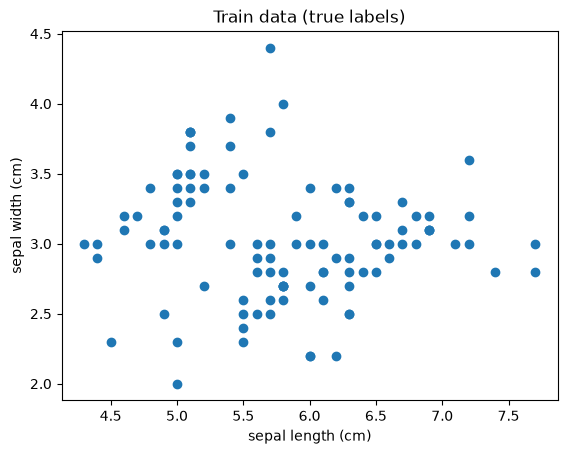

In [60]:
import matplotlib.pyplot as plt

# Quick scatter of two features (train, true labels)
x1 = X.columns[0]
x2 = X.columns[1]
plt.scatter(X_train[x1], X_train[x2])
plt.xlabel(x1)
plt.ylabel(x2)
plt.title('Train data (true labels)')
plt.show()

4. Standardize Data (scikit-learn)

In [ ]:
from sklearn.preprocessing import StandardScaler
# Standardize
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
print(f"Scaler mean after fit: (mean: {scaler.mean_}, var: {scaler.var_})")

X_test_s = scaler.transform(X_test)

Scaler mean after fit: (mean: [5.87333333 3.0552381  3.7847619  1.20571429], var: [0.7375746  0.20704399 3.15252971 0.59882449])


5. Visualize Standardized Data (matplotlib)

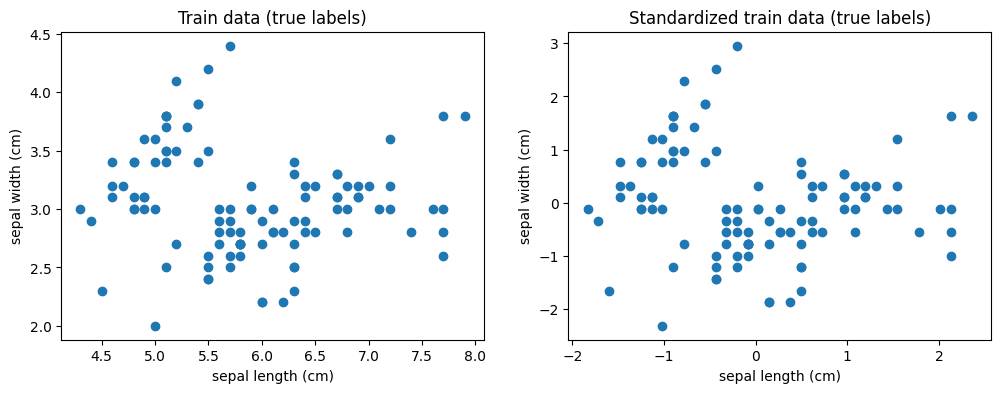

In [ ]:
# let's create side-by-side plots for better comparison
fig, ax = plt.subplots(1, 2, figsize=(12,4))

ax[0].scatter(X_train[x1], X_train[x2])
ax[0].set_xlabel(x1)
ax[0].set_ylabel(x2)
ax[0].set_title('Train data (true labels)')

ax[1].scatter(X_train_s[:,0], X_train_s[:,1])
ax[1].set_xlabel(x1)
ax[1].set_ylabel(x2)
ax[1].set_title('Standardized train data (true labels)')
plt.show()

6. Apply K-Means (scikit-learn)

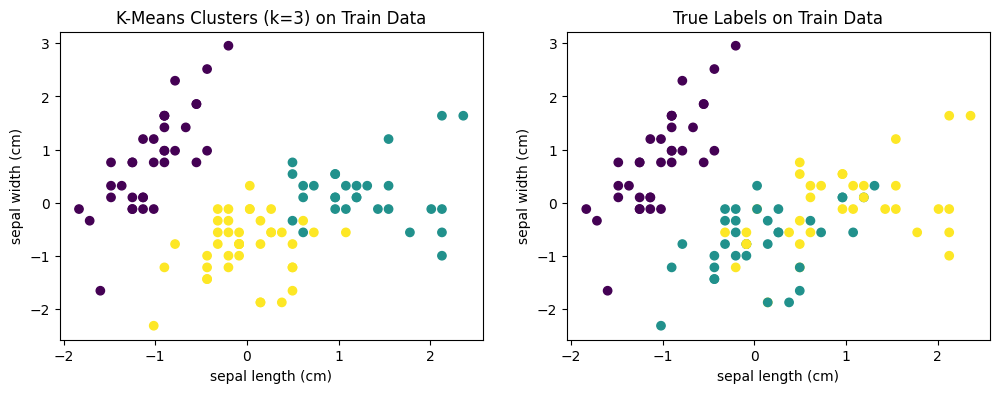

In [ ]:
# K-Means
# Let's try with 2, 3, and 4 clusters and see which one works best
from sklearn.cluster import KMeans

k = 3
kmeans = KMeans(n_clusters=k, random_state=42)
kmeans.fit(X_train_s)
train_clusters = kmeans.labels_

# Visualize clusters
fig, ax = plt.subplots(1, 2, figsize=(12,4))
ax[0].scatter(X_train_s[:,0], X_train_s[:,1], c=train_clusters, cmap='viridis')
ax[0].set_xlabel(x1)
ax[0].set_ylabel(x2)
ax[0].set_title(f'K-Means Clusters (k={k}) on Train Data')

ax[1].scatter(X_train_s[:,0], X_train_s[:,1], c=y_train, cmap='viridis')
ax[1].set_xlabel(x1)
ax[1].set_ylabel(x2)
ax[1].set_title('True Labels on Train Data')
plt.show()

7. Inference and visualize test data (matplotlib)


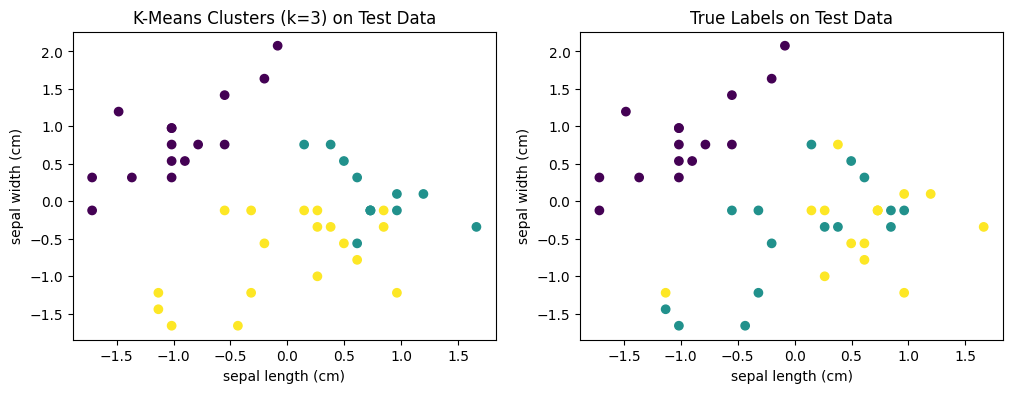

In [ ]:
test_clusters = kmeans.predict(X_test_s)

# Visualize test data clusters
fig, ax = plt.subplots(1, 2, figsize=(12,4))
ax[0].scatter(X_test_s[:,0], X_test_s[:,1], c=test_clusters, cmap='viridis')
ax[0].set_xlabel(x1)
ax[0].set_ylabel(x2)
ax[0].set_title(f'K-Means Clusters (k={k}) on Test Data')
ax[1].scatter(X_test_s[:,0], X_test_s[:,1], c=y_test, cmap='viridis')
ax[1].set_xlabel(x1)
ax[1].set_ylabel(x2)
ax[1].set_title('True Labels on Test Data')
plt.show()

#   Exercise 1

In [1]:
# LOAD ALL LIBRARIES
import pandas as pd
import matplotlib.pyplot as plt


## Read file excel "User.xlsx"

Load the Users.xls file into the Disk on the left in the File Section (Folder Icon). Next, read the file using pandas by passing the path.

In [2]:
data_path = "data/Users.xls"

users_data = pd.read_excel(data_path) # extract the data from the excel file through excel

In a Jupyter Notebook cell, you can print a subset of the representation by simply calling the name of the variable containing the DataFrame.

In [3]:
# print dataset
users_data 

,Age,Workclass,FlnWgt,Education,Education-Num,Marital Status,Occupation,Relationship,Race,Sex,Capital Gain,Capital loss,Hours-per-week,Native Country,Class
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,Basic
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,Basic
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,Basic
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,Basic
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,Basic
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,Basic
32557,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,Premium
32558,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,Basic
32559,22,Private,201490,HS-grad,9,Never-married,Adm-clerical,Own-child,White,Male,0,0,20,United-States,Basic


Remove duplicated elements (it is an method of DataFrame).

In [4]:
# pd.drop_duplicates() remove duplicates from a DataFrame
cleaned_data = pd.DataFrame.drop_duplicates(users_data)

cleaned_data.head(10) # take the first 10 lines of the DataFrame

cleaned_data.tail(10) # take the las 10 lines of the file

# filter only people that are more than 30 years old and show only Age and Workclass
# new_data = cleaned_data.loc[cleaned_data["Age"] > 30, "Workclass"]

cleaned_data

,Age,Workclass,FlnWgt,Education,Education-Num,Marital Status,Occupation,Relationship,Race,Sex,Capital Gain,Capital loss,Hours-per-week,Native Country,Class
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,Basic
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,Basic
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,Basic
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,Basic
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,Basic
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,Basic
32557,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,Premium
32558,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,Basic
32559,22,Private,201490,HS-grad,9,Never-married,Adm-clerical,Own-child,White,Male,0,0,20,United-States,Basic


# View of the data
To apply a view of data we use matplotlib

In [5]:
cleaned_data

,Age,Workclass,FlnWgt,Education,Education-Num,Marital Status,Occupation,Relationship,Race,Sex,Capital Gain,Capital loss,Hours-per-week,Native Country,Class
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,Basic
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,Basic
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,Basic
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,Basic
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,Basic
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,Basic
32557,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,Premium
32558,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,Basic
32559,22,Private,201490,HS-grad,9,Never-married,Adm-clerical,Own-child,White,Male,0,0,20,United-States,Basic


## Select Label and apply encoding

Separate the dataset into features, referred to as X, and labels, referred to as y.

In [ ]:
X = cleaned_data.drop(columns=['Class', 'Age', 'FlnWgt','Education', 'Education-Num', 'Capital Gain', 'Capital loss', 'Hours-per-week', 'Marital Status', 'Occupation'])
y = cleaned_data[['Class']].copy()

# assert no column in X is equivalent to y
for col in X.columns:
   assert not X[col].equals(y), f"Column {col} is equivalent to target y, you should remove it from X"
X # features data we are use for training
# y # label we want to predict

,Workclass,Education,Occupation,Relationship,Race,Sex,Native Country
0,State-gov,Bachelors,Adm-clerical,Not-in-family,White,Male,United-States
1,Self-emp-not-inc,Bachelors,Exec-managerial,Husband,White,Male,United-States
2,Private,HS-grad,Handlers-cleaners,Not-in-family,White,Male,United-States
3,Private,11th,Handlers-cleaners,Husband,Black,Male,United-States
4,Private,Bachelors,Prof-specialty,Wife,Black,Female,Cuba
...,...,...,...,...,...,...,...
32556,Private,Assoc-acdm,Tech-support,Wife,White,Female,United-States
32557,Private,HS-grad,Machine-op-inspct,Husband,White,Male,United-States
32558,Private,HS-grad,Adm-clerical,Unmarried,White,Female,United-States
32559,Private,HS-grad,Adm-clerical,Own-child,White,Male,United-States


## Pre-Processing
Afterwards, utilize Label Encoder to encode the categorical features.

> *Hint:* To identify categorical columns, you can use pandas functions or simply inspect the data. For label encoding, Scikit-learn's provides a dedicated class.

In [65]:
from sklearn.preprocessing import LabelEncoder
# to see categories from a column in pandas we use the pd.Categorical
label_encoder = LabelEncoder()
y_transformed = label_encoder.fit_transform(y)
X_relationship = pd.Series(label_encoder.fit_transform(X['Relationship']))
X_sex = pd.Series(label_encoder.fit_transform(X['Sex']))
X_race = pd.Series(label_encoder.fit_transform(X['Race']))

y_transformed # now we have transform our data from Basic / Premium to 0/1
X_transformed = pd.concat([X_relationship, X_sex, X_race], axis=1, names=['Relationship', 'Sex', 'Race'])
X_transformed

/Users/daniloquattrini/Documents/university-polito/laboratory/data-science/users-data-analysis/.venv/lib/python3.14/site-packages/sklearn/preprocessing/_label.py:120: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


,0,1,2
0,1,1,4
1,0,1,4
2,1,1,4
3,0,1,2
4,5,0,2
...,...,...,...
32532,5,0,4
32533,0,1,4
32534,4,0,4
32535,3,1,4


##  Use the decision tree classifier model.

> *Hint:* Use DecisionTreeClassifier() and its .fit function

In [67]:
# Initialized a train test in order to perform the model validation
from sklearn.model_selection import train_test_split
# Initialize the Decision Tree Classifier, set criterion and max depth
from sklearn.tree import DecisionTreeClassifier

# Create train and test variables for the features X and label y
# test_size the percentage of the DataFrame we use for the test in this case the 70% of the X Dataframe is for testing 30% is not used for training
X_test, X_train, y_test, y_train = train_test_split(X_transformed, y_transformed, test_size=0.30, random_state=43)

# Now we use the Decision tree classifier
dct = DecisionTreeClassifier()

dct.fit(X_test, y_test)


,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of sampl

Goal: Control the model complexity (depth) and see the overall accuracy on the training set.

##  Print the structure of the decision tree

In [ ]:
# Define figure


# use plot_tree from sklearn


In [ ]:
# Decision tree depth (it is an attribute)


## Exercise 2

Impact of the hyper-parameters: Evaluate the Tree by combining different `max depth` and `min_impurity` values

> *Hint:* use two nested loops and store the performance with the method `.score()` of the decision tree object.

In [ ]:
max_depths = ...
min_impurities = ...

...

# Exercise 3

We now want to evaluate the performance of our Decision Tree model using another target feature: **Native country**. Repeat Exercise 1-2 using this feature as target. Compare the results with the previous target feature.

# Exercise 4-5

## Validation of a classification model using Cross Validation

Cross-validation is a technique used to assess the performance and generalization ability of machine learning models, particularly in the context of classification tasks. It involves partitioning the dataset into multiple subsets, known as folds.

1. **Partitioning the Dataset**: The dataset is divided into k equal-sized folds.

2. **Training and Testing**: The model is trained k times, each time using k-1 folds for training and the remaining fold for testing.

3. **Evaluation**: The performance of the model is evaluated on each fold, and the results are averaged to obtain a robust estimate of the model's performance.

4. **Advantages**: Cross-validation provides a more reliable estimate of the model's performance compared to a single train-test split. It helps to detect overfitting and assesses the model's ability to generalize to unseen data.

> *Hint:* Use `cross_val_score` and `cross_val_predict` to perform cross-validation easily. Follow the same instruction of Exercise 1 to initialise and use the model

In [ ]:
# We now want again to predict `class` feature

assert 'class' not in X.columns and y.name == 'class', "Feature 'class' should be the target variable y"

### Decision Tree with Cross Validation

In [ ]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, accuracy_score

# Initialize the decision tree classifier

# Perform cross-validation predictions

# Confusion matrix

# Evaluate accuracy

### K-NN with Cross Validation

**Warning**: K-NN requires data standardization before training and testing.

In [ ]:
# Initialize the decision K-NN classifier
from sklearn.neighbors import KNeighborsClassifier

# Perform StandardScaler

# Perform cross-validation predictions

# Confusion matrix

# Evaluate accuracy

### Naive Bayes Classifier with Cross Validation

In [ ]:
# Initialize the Naive Bayes classifier
from sklearn.naive_bayes import GaussianNB

# Perform cross-validation predictions

# Confusion matrix

# Evaluate accuracy

# Exercise 6

In [ ]:
# Perform Correlation Analysis using only numerical features
